# Egyptian Premier League vs the World: 10 Seasons of Data (2015-2025)

**My first data analysis project.** I took 10 seasons of Egyptian Premier League match data,
asked simple questions with pandas, matplotlib and seaborn, and then compared the answers
with the English Premier League over the same 10 seasons.

The questions:

1. How many goals does the Egyptian league score, and is that changing?
2. Does playing at home really help in Egypt?
3. Who actually dominates the league?
4. Who are the best scorers of the decade?
5. Which team had the best defense?
6. How close are the matches?
7. **Egypt vs England: what is actually different between the two leagues?**

**Data:**
- Egyptian league: [10 Seasons Egyptian League](https://www.kaggle.com/datasets/ahmedaelgohary/10-seasons-egyptian-league)
  by Ahmed Elgohary on Kaggle (license: Open Database License / Database Contents License).
  2,907 matches with results, every goal scorer, referees and stadiums.
- English league: [football-data.co.uk](https://www.football-data.co.uk/data.php) match CSVs,
  one per season (3,800 matches, free for personal/educational use), plus a Kaggle
  [goal-level EPL dataset](https://www.kaggle.com/datasets/nico2890/football-10-years-of-epl-with-goal-timing)
  for the penalty comparison (license not stated on the page; used with attribution).

**Coverage caveats I found while cleaning:**
- Egyptian season 2024-2025 is partial: 153 matches, up to 29 April 2025. I use it for
  per-match stats but not for season totals or champions.
- The Egyptian goals table lists 6,635 goals while the results table implies 6,645 - a
  10-goal difference (0.15%), so scorer rankings are still trustworthy.
- Scorers are merged by exact name, which merges namesakes: I verified the top 10
  club-by-club and split out 20 goals belonging to two different players (details in section 5).
- 24 Egyptian matches (0.8%) have no stadium/referee info; the rest of the stadium table
  covers all 10 seasons.
- The EPL goal-level file covers 2015-16 to 2022-23, so the penalty comparison uses those
  8 seasons on both sides.


## 0. Setup: load the data

Standard data-analysis stack: **pandas** for tables, **matplotlib + seaborn** for charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Egyptian league: 3 tables, already combined across all 10 seasons
results = pd.read_csv('data/result_combined.csv')   # one row per match
goals   = pd.read_csv('data/goals_combined.csv')    # one row per goal
venues  = pd.read_csv('data/refandstadium_combined.csv')  # referee + stadium per match

print('matches:', results.shape, '| goals:', goals.shape, '| venues:', venues.shape)
results.head()

matches: (2907, 12) | goals: (6635, 11) | venues: (2907, 4)


,match_id,Gameweek,Date,Time,Result,Home team,Away team,Day,HomeGoals,AwayGoals,Status,Season
0,2015000,1,2015-10-20,5:00 PM,2:0,El Dakhlia,El Mokawloon,Tue,2,0,HomeWin,2015-2016
1,2015001,1,2015-10-20,7:45 PM,2:2,Enppi SC,Harras Hodoud,Tue,2,2,Tie,2015-2016
2,2015002,1,2015-10-21,2:45 PM,1:0,Ittihad Alex,Aswan SC,Wed,1,0,HomeWin,2015-2016
3,2015003,1,2015-10-21,5:00 PM,2:0,Ismaily,Entag El Harby,Wed,2,0,HomeWin,2015-2016
4,2015004,1,2015-10-21,7:45 PM,2:0,Zamalek,Wadi Degla,Wed,2,0,HomeWin,2015-2016


## 1. Cleaning

Four checks I always do first: correct data types, no duplicates, missing values, and whether
columns that should agree actually agree.

In [2]:
# 1. Turn the Date column from text into real dates so we can sort and group by time
results['Date'] = pd.to_datetime(results['Date'])

# 2. Duplicate matches? (match_id should be unique)
print('duplicate matches:', results.duplicated(subset='match_id').sum())

# 3. Missing values per column
print('\nmissing values:')
print(results.isnull().sum())

duplicate matches: 0

missing values:
match_id       0
Gameweek       0
Date           0
Time         455
Result         0
Home team      0
Away team      0
Day            0
HomeGoals      0
AwayGoals      0
Status         0
Season         0
dtype: int64


In [3]:
# 4. Sanity check: does the Status column (HomeWin/Tie/AwayWin) agree with the goals?
def real_status(match):
    if match['HomeGoals'] > match['AwayGoals']:
        return 'HomeWin'
    elif match['AwayGoals'] > match['HomeGoals']:
        return 'AwayWin'
    return 'Tie'

check = results.apply(real_status, axis=1)
print('rows where Status disagrees with the score:', (check != results['Status']).sum())

# Add a helper column: total goals in the match
results['TotalGoals'] = results['HomeGoals'] + results['AwayGoals']

# Season 2024-2025 is still running in this dataset, so keep it separate for season comparisons
full_seasons = sorted(s for s in results['Season'].unique() if s != '2024-2025')
print('\nfull seasons:', len(full_seasons), '| partial season matches:',
      (results['Season'] == '2024-2025').sum())

# Short season labels (2015-16 style) to match the English dataset later
results['SeasonShort'] = results['Season'].str[:4] + '-' + results['Season'].str[7:9]
goals['SeasonShort'] = goals['Season'].str[:4] + '-' + goals['Season'].str[7:9]

rows where Status disagrees with the score: 0

full seasons: 9 | partial season matches: 153


Cleaning result: no duplicates, goals columns are complete, `Status` agrees with the score
in all 2,907 matches. Only kick-off `Time` has 455 missing values, and I don't need it for
these questions. The data is clean enough to trust.

## 2. How many goals does the league score?

First question: is the Egyptian league getting more or less attacking over the decade?

In [4]:
# Group by season and count matches and goals
per_season = results.groupby('SeasonShort').agg(
    matches=('match_id', 'count'),
    goals=('TotalGoals', 'sum'),
)
per_season['goals_per_match'] = per_season['goals'] / per_season['matches']
per_season.round(2)

,matches,goals,goals_per_match
SeasonShort,,,
2015-16,306,676,2.21
2016-17,306,690,2.25
2017-18,306,718,2.35
2018-19,306,729,2.38
2019-20,306,692,2.26
2020-21,306,765,2.50
2021-22,306,673,2.20
2022-23,306,657,2.15
2023-24,306,730,2.39


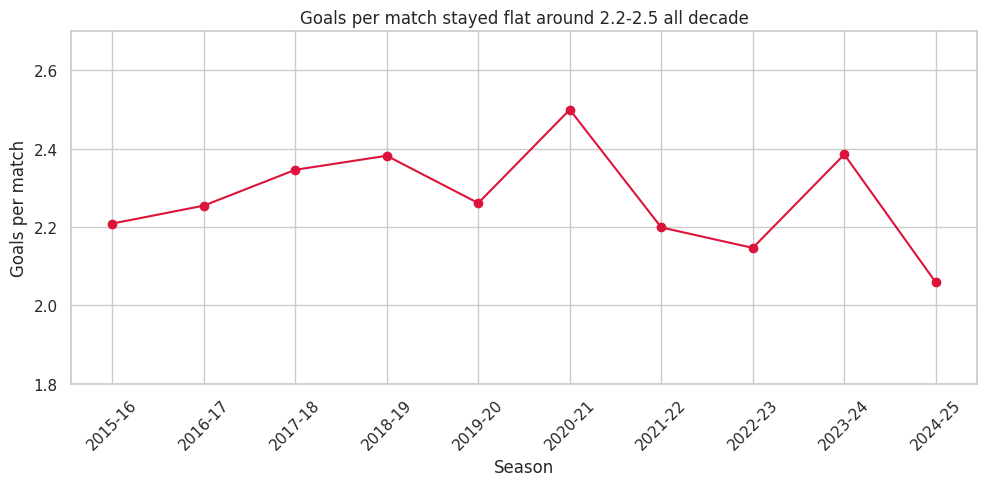

league average: 2.29 goals per match
highest: 2020-21 - 2.5
lowest : 2024-25 - 2.06 (partial season)


In [5]:
fig, ax = plt.subplots()
ax.plot(per_season.index, per_season['goals_per_match'], marker='o', color='crimson')
ax.set_title('Goals per match stayed flat around 2.2-2.5 all decade')
ax.set_xlabel('Season')
ax.set_ylabel('Goals per match')
ax.set_ylim(1.8, 2.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('league average:', round(results['TotalGoals'].mean(), 2), 'goals per match')
print('highest:', per_season['goals_per_match'].idxmax(), '-', round(per_season['goals_per_match'].max(), 2))
print('lowest :', per_season['goals_per_match'].idxmin(), '-', round(per_season['goals_per_match'].min(), 2), '(partial season)')

The league scores about **2.29 goals per match** on average, and that barely moved in 10
years. Keep this number in mind - it becomes interesting when we compare with England in
section 8.

## 3. Does home advantage exist in Egypt?

In most leagues the home team wins about 44-46% of matches. Let's check Egypt.

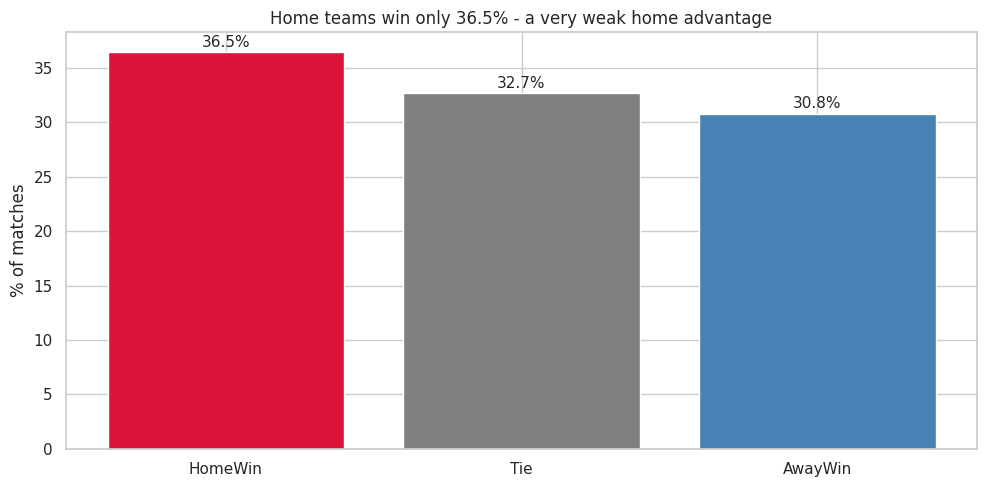

average goals per match - home: 1.21 | away: 1.08


In [6]:
# Overall: who wins how often?
outcome_pct = results['Status'].value_counts(normalize=True) * 100

fig, ax = plt.subplots()
colors = {'HomeWin': 'crimson', 'Tie': 'gray', 'AwayWin': 'steelblue'}
ax.bar(outcome_pct.index, outcome_pct.values, color=[colors[i] for i in outcome_pct.index])
ax.set_title('Home teams win only 36.5% - a very weak home advantage')
ax.set_ylabel('% of matches')
for i, v in enumerate(outcome_pct.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

print('average goals per match - home:', round(results['HomeGoals'].mean(), 2),
      '| away:', round(results['AwayGoals'].mean(), 2))

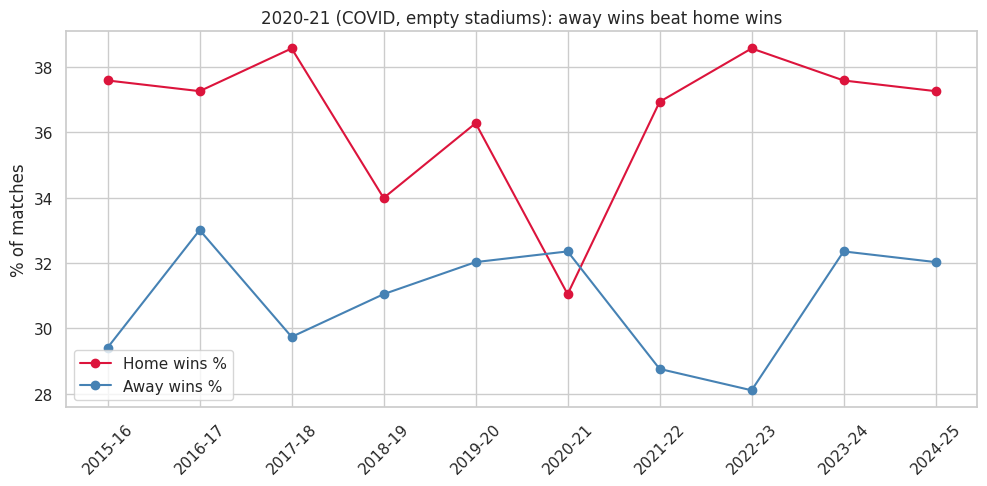

2020-2021: {'Tie': 112, 'AwayWin': 99, 'HomeWin': 95}


In [7]:
# Did this change per season?
home_away = results.groupby('SeasonShort').apply(
    lambda d: pd.Series({
        'Home wins %': 100 * (d['Status'] == 'HomeWin').mean(),
        'Away wins %': 100 * (d['Status'] == 'AwayWin').mean(),
    }), include_groups=False)

fig, ax = plt.subplots()
ax.plot(home_away.index, home_away['Home wins %'], marker='o', color='crimson', label='Home wins %')
ax.plot(home_away.index, home_away['Away wins %'], marker='o', color='steelblue', label='Away wins %')
ax.set_title('2020-21 (COVID, empty stadiums): away wins beat home wins')
ax.set_ylabel('% of matches')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

s2021 = results[results['Season'] == '2020-2021']['Status'].value_counts()
print('2020-2021:', s2021.to_dict())

Two takeaways here. First, home advantage in Egypt (36.5% home wins) is much weaker than
elsewhere. Second, the data *sees* COVID: in 2020-21, played in empty stadiums, away teams
won more often (99) than home teams (95) - the only season in the decade where that happened.

### Why is home advantage so weak? The answer is a club-by-club story

The league average (36.5%) hides the real story. Some Egyptian clubs have a true home ground;
others have been playing "home" matches in borrowed stadiums, sometimes in other cities, for
years. The stadium table covers all 10 seasons, so we can measure this per club.

First the summary numbers, just to see the scale:

In [8]:
# How many different stadiums has each club used as the HOME team?
with_stadiums = results.merge(venues[['match_id', 'Stadium']], on='match_id', how='inner')
stadiums_per_team = with_stadiums.groupby('Home team')['Stadium'].nunique()

print('average stadiums used as "home" per club:', round(stadiums_per_team.mean(), 1))
print('clubs that used 4 or more different "home" stadiums:',
      (stadiums_per_team >= 4).sum(), 'of', len(stadiums_per_team))

top_stadiums = venues['Stadium'].value_counts()
share_top3 = 100 * top_stadiums.head(3).sum() / len(venues)
print(f'the top 3 mega-venues (Petrosport, Borg El Arab, Cairo International) host {share_top3:.0f}% of ALL matches')

# Per club: how many stadiums, and what share at their most-used one?
per_club = with_stadiums.groupby('Home team')['Stadium'].agg(
    stadiums='nunique', main_stadium=lambda s: s.value_counts().index[0],
    main_share=lambda s: round(100 * s.value_counts().iloc[0] / len(s)))
per_club.sort_values('stadiums', ascending=False).head(10)

average stadiums used as "home" per club: 5.1
clubs that used 4 or more different "home" stadiums: 22 of 37
the top 3 mega-venues (Petrosport, Borg El Arab, Cairo International) host 33% of ALL matches


,stadiums,main_stadium,main_share
Home team,,,
Talaea El Gaish,10,Gehaz El Reyada Stadium,79
El Makasa,9,Fayoum Stadium,34
Wadi Degla,9,Petrosport Stadium,36
Aswan SC,9,Aswan Stadium,76
El Masry,8,Borg El Arab Stadium,57
Zamalek,8,Cairo International Stadium,57
Petrojet,8,Suez Stadium,66
El Mokawloon,8,Arab Contractors Stadium,88
Entag El Harby,8,El Salam Stadium,83


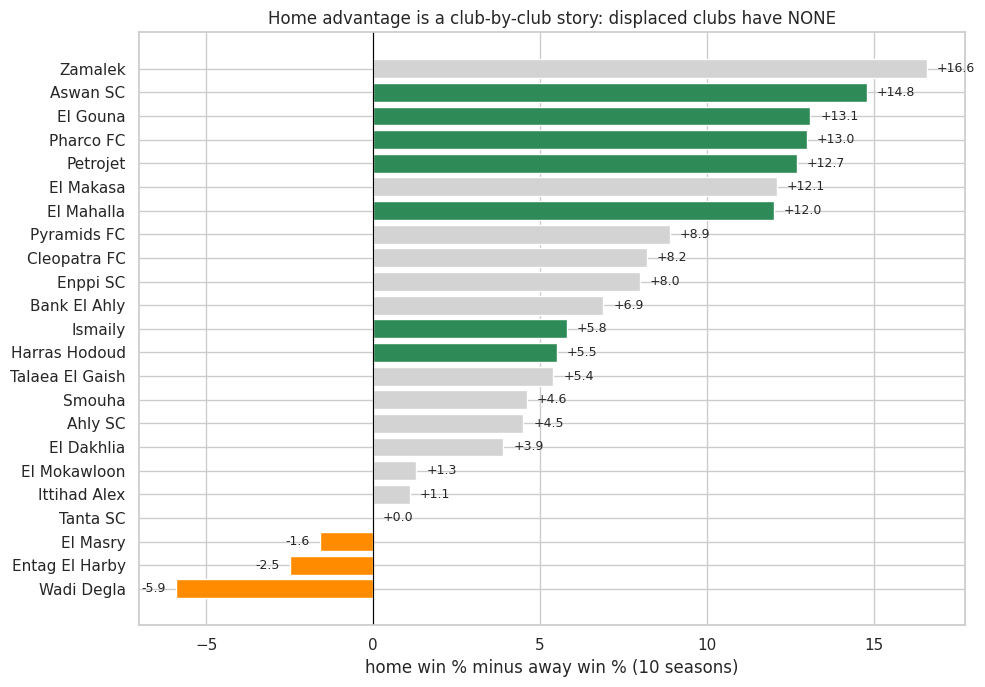

orange = displaced clubs | green = provincial clubs with a real home ground
El Masry: 8 "home" stadiums, none of them in Port Said - home 39.8%, away 41.4%


In [9]:
# Now the key test per club: home win % MINUS away win % (their real home advantage)
clubs = []
for team in sorted(set(results['Home team'])):
    home = with_stadiums[with_stadiums['Home team'] == team]
    away = results[results['Away team'] == team]
    if len(home) < 50:          # keep only clubs with enough matches to trust the %
        continue
    home_wp = 100 * (home['Status'] == 'HomeWin').mean()
    away_wp = 100 * (away['Status'] == 'AwayWin').mean()
    clubs.append({'team': team, 'stadiums': home['Stadium'].nunique(),
                  'home_win': round(home_wp, 1), 'away_win': round(away_wp, 1),
                  'advantage': round(home_wp - away_wp, 1)})
club_adv = pd.DataFrame(clubs).sort_values('advantage')

displaced = ['El Masry', 'Wadi Degla', 'Entag El Harby']
provincial = ['Ismaily', 'Petrojet', 'Aswan SC', 'El Mahalla', 'Harras Hodoud', 'El Gouna', 'Pharco FC']
colors = ['darkorange' if t in displaced else 'seagreen' if t in provincial else 'lightgray'
          for t in club_adv['team']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(club_adv['team'], club_adv['advantage'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Home advantage is a club-by-club story: displaced clubs have NONE')
ax.set_xlabel('home win % minus away win % (10 seasons)')
for i, v in enumerate(club_adv['advantage']):
    ax.text(v + 0.3 if v >= 0 else v - 0.3, i, f'{v:+.1f}',
            va='center', ha='left' if v >= 0 else 'right', fontsize=9)
plt.tight_layout()
plt.show()

print('orange = displaced clubs | green = provincial clubs with a real home ground')
print('El Masry: 8 "home" stadiums, none of them in Port Said - home 39.8%, away 41.4%')

The contrast the league average was hiding:

- **El Masry (Port Said) is the extreme case.** Over 10 seasons they played "home" matches in
  **8 different stadiums - none of them in Port Said**; their most-used "home" ground is Borg
  El Arab Stadium *in Alexandria, a different city* (91 of 161 matches). Their home win rate
  (39.8%) is actually LOWER than their away win rate (41.4%) - a negative home advantage.
  Context from outside the dataset: Port Said clubs were banned from playing at home for
  years after the 2012 Port Said stadium disaster. That is history the dataset doesn't state,
  but the 8-stadiums-none-at-home pattern is exactly what such a ban looks like in data.
- **Wadi Degla and Entag El Harby** (Cairo clubs that rent mega-venues) also have negative
  home advantage (-5.9 and -2.5). Wadi Degla used 9 "home" stadiums, and only 36% of their
  "home" games were even at their most-used one.
- **Provincial clubs with one true home ground show the normal pattern**: Aswan +14.8,
  El Gouna +13.1, Pharco +13.0, Petrojet +12.7, El Mahalla +12.0, Ismaily +5.8 - averaging
  **+8.1**, close to a normal league. The advantage exists in Egypt; it only exists where a
  real home does.
- Al Ahly (74.7%) and Zamalek (67.3%) win everywhere, home or away, because they're simply
  stronger - stadium sharing doesn't hurt them the way it hurts everyone else.

On top of the venue story, context outside the dataset: Egyptian stadiums have had heavy
attendance restrictions for years, so crowds are often small or absent even when the match is
technically "at home". The dataset has no attendance figures to prove that directly, but it
agrees with it - see the COVID season above, and the England comparison in section 8, where
the same empty-stadium effect appears.

## 4. Who actually dominates the league?

The dataset has no standings table, so I'll **build the league table myself from the raw
results**: 3 points for a win, 1 for a draw. This is a classic pandas exercise and my favorite
part of the project.

In [10]:
def build_league_table(matches, home_col='Home team', away_col='Away team',
                       hg_col='HomeGoals', ag_col='AwayGoals'):
    # one dictionary of stats per team
    table = {}
    for _, match in matches.iterrows():
        home, away = match[home_col], match[away_col]
        hg, ag = match[hg_col], match[ag_col]

        for team in (home, away):
            if team not in table:
                table[team] = {'P': 0, 'W': 0, 'D': 0, 'L': 0, 'GF': 0, 'GA': 0, 'Pts': 0}

        home_row, away_row = table[home], table[away]
        home_row['P'] += 1
        away_row['P'] += 1
        home_row['GF'] += hg   # goals for / against
        home_row['GA'] += ag
        away_row['GF'] += ag
        away_row['GA'] += hg

        if hg > ag:        # home win: 3 points to home
            home_row['W'] += 1
            home_row['Pts'] += 3
            away_row['L'] += 1
        elif hg < ag:      # away win: 3 points to away
            away_row['W'] += 1
            away_row['Pts'] += 3
            home_row['L'] += 1
        else:              # draw: 1 point each
            home_row['D'] += 1
            away_row['D'] += 1
            home_row['Pts'] += 1
            away_row['Pts'] += 1

    table_df = pd.DataFrame(table).T                # teams become rows
    table_df['GD'] = table_df['GF'] - table_df['GA']
    # official tie-break order: points, then goal difference, then goals scored
    return table_df.sort_values(['Pts', 'GD', 'GF'], ascending=False)

# Test it on one season
table_2024 = build_league_table(results[results['Season'] == '2023-2024'])
table_2024.head()

,P,W,D,L,GF,GA,Pts,GD
Ahly SC,34,27,4,3,75,28,85,47
Pyramids FC,34,24,7,3,62,27,79,35
Zamalek,34,17,8,9,53,37,59,16
El Masry,34,16,7,11,41,39,55,2
Modern Future,34,14,12,8,40,28,54,12


          Champion Points
2015-2016  Ahly SC     76
2016-2017  Ahly SC     84
2017-2018  Ahly SC     88
2018-2019  Ahly SC     80
2019-2020  Ahly SC     89
2020-2021  Zamalek     80
2021-2022  Zamalek     77
2022-2023  Ahly SC     83
2023-2024  Ahly SC     85

titles 2015-2024: {'Ahly SC': 7, 'Zamalek': 2}


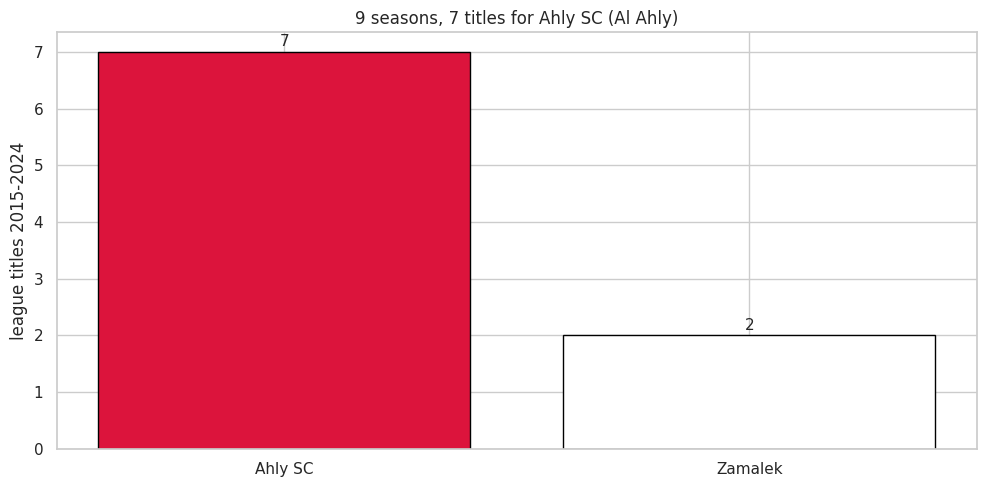

In [11]:
# Now the champion of every complete season
champions = {}
for season in full_seasons:
    table = build_league_table(results[results['Season'] == season])
    champions[season] = (table.index[0], int(table['Pts'].iloc[0]))

champs = pd.DataFrame(champions, index=['Champion', 'Points']).T
print(champs)
print('\ntitles 2015-2024:', champs['Champion'].value_counts().to_dict())

fig, ax = plt.subplots()
counts = champs['Champion'].value_counts()
ax.bar(counts.index, counts.values, color=['crimson', 'white', 'steelblue'][:len(counts)],
       edgecolor='black')
ax.set_title('9 seasons, 7 titles for Ahly SC (Al Ahly)')
ax.set_ylabel('league titles 2015-2024')
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.1, str(v), ha='center')
plt.tight_layout()
plt.show()

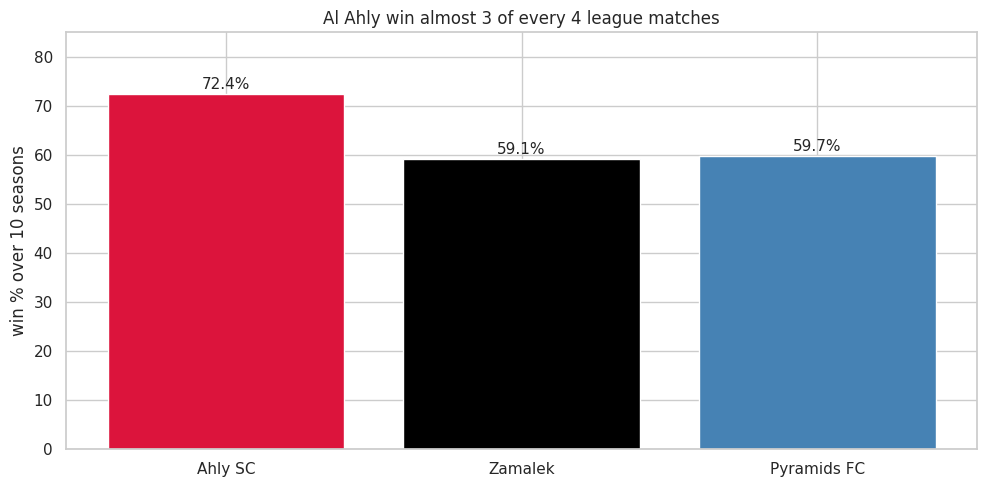

,Team,Played,Wins,Win %
0,Ahly SC,323,234,72.4
1,Zamalek,323,191,59.1
2,Pyramids FC,221,132,59.7


In [12]:
# How far ahead are the traditional big two plus Pyramids, match by match?
big_three = ['Ahly SC', 'Zamalek', 'Pyramids FC']
rows = []
for team in big_three:
    played = results[(results['Home team'] == team) | (results['Away team'] == team)]
    wins = ((played['Home team'] == team) & (played['Status'] == 'HomeWin')).sum() + \
           ((played['Away team'] == team) & (played['Status'] == 'AwayWin')).sum()
    rows.append({'Team': team, 'Played': len(played), 'Wins': int(wins),
                 'Win %': round(100 * wins / len(played), 1)})
big3 = pd.DataFrame(rows)

fig, ax = plt.subplots()
ax.bar(big3['Team'], big3['Win %'], color=['crimson', 'black', 'steelblue'])
ax.set_title('Al Ahly win almost 3 of every 4 league matches')
ax.set_ylabel('win % over 10 seasons')
ax.set_ylim(0, 85)
for i, v in enumerate(big3['Win %']):
    ax.text(i, v + 1, f'{v}%', ha='center')
plt.tight_layout()
plt.show()
big3

Al Ahly won **7 of the 9 completed titles** (Zamalek the other 2, in 2020-21 and 2021-22)
and win **72.4%** of all their league matches across the decade. Zamalek and Pyramids are at
about 59-60%. This is one of the most dominant club records anywhere in world football.

## 5. Who are the best scorers of the decade?

The goals table has one row per goal, with the scorer, whether it was an own goal, and whether
it was a penalty. Own goals should never count for the scorer, so I filter them out.

removed 20 goals that belong to namesake players


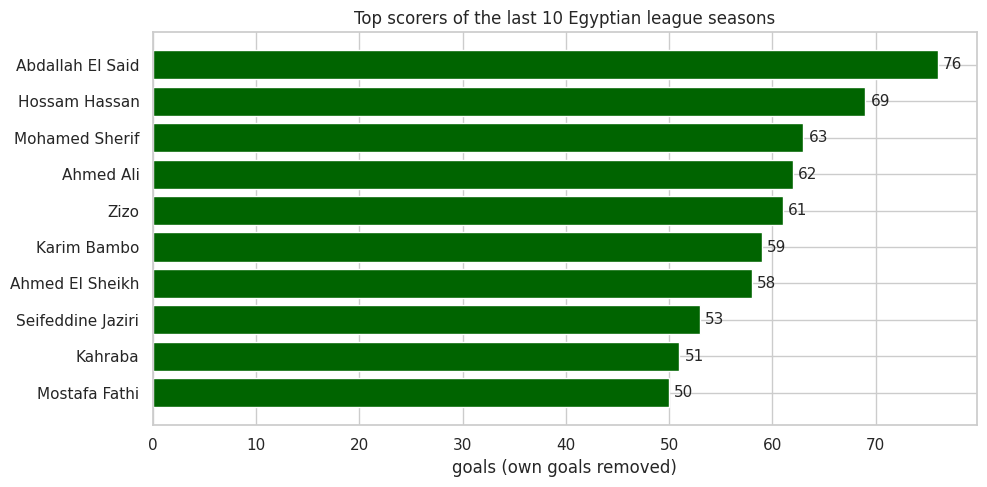

GoalScorer
Abdallah El Said     76
Hossam Hassan        69
Mohamed Sherif       63
Ahmed Ali            62
Zizo                 61
Karim Bambo          59
Ahmed El Sheikh      58
Seifeddine Jaziri    53
Kahraba              51
Mostafa Fathi        50
Name: count, dtype: int64

In [13]:
# Real goals only: own goals count AGAINST the scorer's team, not for them
clean_goals = goals[~goals['OG']]

# DATA QUALITY CHECK: grouping by exact name merges players who SHARE a name.
# I verified the top names club-by-club against Wikipedia/Transfermarkt and found 2 merges:
#  - 8 goals for El Sharkia in 2016-17 under 'Hossam Hassan': the Smouha striker (born 1993)
#    played for Smouha all season. These belong to a DIFFERENT Hossam Hassan (a defensive
#    midfielder born 1989, on El Sharkia's 2016-17 roster; 6 of the 8 were penalties - the
#    team's designated penalty taker).
#  - 12 goals for El Dakhlia under 'Zizo': Ahmed Sayed 'Zizo' was in Belgium/Portugal until
#    January 2019 and then joined Zamalek, so El Dakhlia's 'Zizo' is a different player.
namesake_goals = ((clean_goals['GoalScorer'] == 'Hossam Hassan') & (clean_goals['TeamScored'] == 'El Sharkia')) |                  ((clean_goals['GoalScorer'] == 'Zizo') & (clean_goals['TeamScored'] == 'El Dakhlia'))
scorer_goals = clean_goals[~namesake_goals]
print('removed', namesake_goals.sum(), 'goals that belong to namesake players')

# The rest of the Hossam Hassan goals form one perfect career: 1 El Dakhlia + 66 Smouha
# + 2 Al Ahly = 69, matching his Wikipedia record exactly (44 for Smouha 2016-2021,
# 22 for Smouha 2023-2025, 2 for Al Ahly 2021-2023).
top_scorers = scorer_goals['GoalScorer'].value_counts().head(10)

fig, ax = plt.subplots()
ax.barh(top_scorers.index[::-1], top_scorers.values[::-1], color='darkgreen')
ax.set_title('Top scorers of the last 10 Egyptian league seasons')
ax.set_xlabel('goals (own goals removed)')
for i, v in enumerate(top_scorers.values[::-1]):
    ax.text(v + 0.5, i, str(v), va='center')
plt.tight_layout()
plt.show()
top_scorers

In [14]:
# Golden boot: top scorer of every season (namesake-checked table again)
boots = []
for season in sorted(results['Season'].unique()):
    season_goals = scorer_goals[scorer_goals['Season'] == season]['GoalScorer'].value_counts()
    boots.append({'Season': season, 'Top scorer': season_goals.index[0],
                  'Goals': int(season_goals.iloc[0])})
golden_boots = pd.DataFrame(boots)
golden_boots

,Season,Top scorer,Goals
0,2015-2016,Hossam Paulo,17
1,2016-2017,Ahmed El Sheikh,20
2,2017-2018,Walid Azaro,18
3,2018-2019,Ahmed Ali,19
4,2019-2020,Abdallah El Said,17
5,2020-2021,Mohamed Sherif,22
6,2021-2022,Zizo,19
7,2022-2023,Mabululu,16
8,2023-2024,Wessam Abou Ali,18
9,2024-2025,Emam Ashour,9


In [15]:
# And how much do penalties matter in a low-scoring league?
penalty_share = 100 * scorer_goals['Penalty'].mean()
print(f'{penalty_share:.1f}% of all goals are penalties')
print('total goals analyzed:', len(scorer_goals))

15.4% of all goals are penalties
total goals analyzed: 6455


**Abdallah El Said is the top scorer of the decade with 76 goals**, followed by Hossam
Hassan (69), Mohamed Sherif (63), Ahmed Ali (62) and Zizo (61).

About that Hossam Hassan: he is NOT the 1966 legend - this is the striker born in 1993 who
became Smouha's all-time league top scorer, then moved to Al Ahly (2021-2023), back to Smouha,
and on to Al Ittihad. His 69 goals here match his documented career exactly (1 El Dakhlia,
66 Smouha, 2 Al Ahly); the dataset's extra 8 'Hossam Hassan' goals at El Sharkia belong to a
namesake, and catching that is exactly the kind of check recruiters like to see. **15.4% of
all goals come from penalties** - about 1 goal in every 6. (2024-25's golden boot number is
mid-season: 9 goals by Emam Ashour at the 29-Apr-2025 cutoff.)

## 6. Which team had the best defense?

Scoring is rare in this league, so defense might matter even more than attack. I reuse my
`build_league_table` function and sort by goals conceded (GA) instead of points.

In [16]:
# Best defense of every season = fewest goals conceded
best_defense = []
for season in sorted(results['Season'].unique()):
    table = build_league_table(results[results['Season'] == season])
    best = table.sort_values('GA').iloc[0]
    best_defense.append({'Season': season, 'Team': table.sort_values('GA').index[0],
                         'Goals conceded': int(best['GA']), 'Matches': int(best['P'])})
defense_df = pd.DataFrame(best_defense)
defense_df

,Season,Team,Goals conceded,Matches
0,2015-2016,Ahly SC,24,34
1,2016-2017,Ahly SC,14,34
2,2017-2018,Ahly SC,19,34
3,2018-2019,Ahly SC,20,34
4,2019-2020,Ahly SC,8,34
5,2020-2021,Zamalek,21,34
6,2021-2022,Ahly SC,21,34
7,2022-2023,Ahly SC,13,34
8,2023-2024,Pyramids FC,27,34
9,2024-2025,Ahly SC,9,17


In [17]:
# Al Ahly 2019-2020 looks unreal - let me double-check it match by match
ahly_1920 = results[(results['Season'] == '2019-2020') &
                    ((results['Home team'] == 'Ahly SC') | (results['Away team'] == 'Ahly SC'))]
conceded = ahly_1920.apply(
    lambda m: m['AwayGoals'] if m['Home team'] == 'Ahly SC' else m['HomeGoals'], axis=1)
print('matches:', len(ahly_1920), '| goals conceded:', conceded.sum(),
      '| matches conceding 0:', (conceded == 0).sum())

matches: 34 | goals conceded: 8 | matches conceding 0: 28


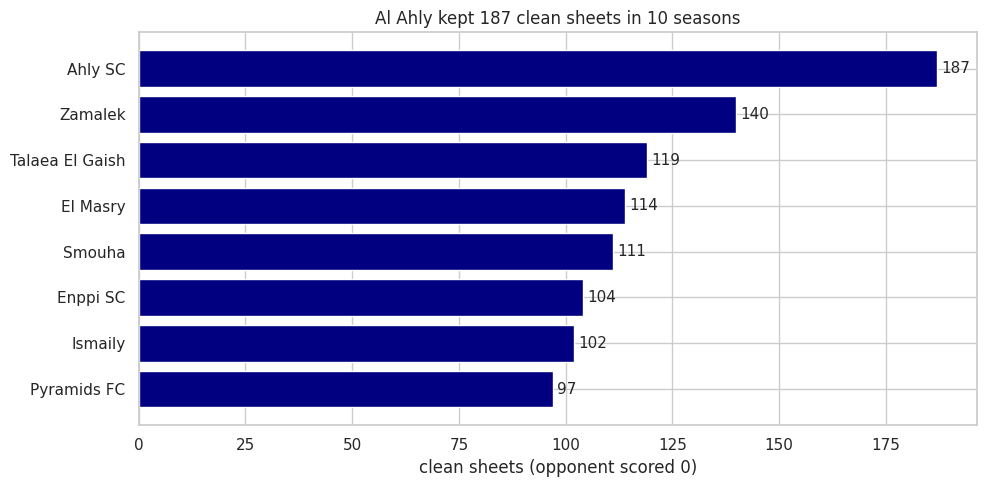

In [18]:
# Clean sheets over the whole decade (all teams)
home_cs = results[results['AwayGoals'] == 0]['Home team'].value_counts()
away_cs = results[results['HomeGoals'] == 0]['Away team'].value_counts()
clean_sheets = (home_cs + away_cs).sort_values(ascending=False).head(8)

fig, ax = plt.subplots()
ax.barh(clean_sheets.index[::-1], clean_sheets.values[::-1], color='navy')
ax.set_title('Al Ahly kept 187 clean sheets in 10 seasons')
ax.set_xlabel('clean sheets (opponent scored 0)')
for i, v in enumerate(clean_sheets.values[::-1]):
    ax.text(v + 1, i, str(v), va='center')
plt.tight_layout()
plt.show()

The single wildest number in the dataset: **Al Ahly in 2019-2020 conceded 8 goals in 34
matches** - a clean sheet in 28 of 34. I re-checked it match by match because I didn't believe
it either. They also have **187 clean sheets** across the decade; the best non-Ahly team
(Zamalek) has 140.

## 7. How close are the matches?

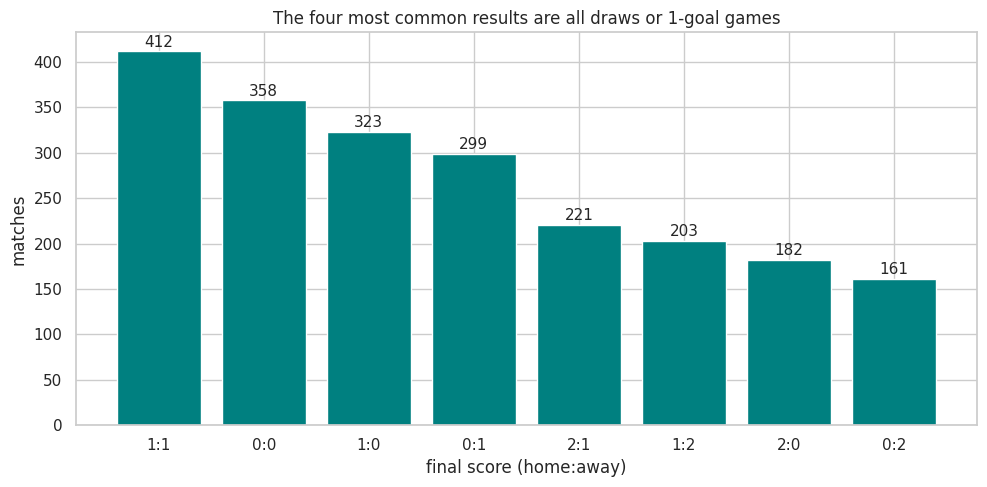

matches decided by 0 or 1 goal: 73.1%
matches ending 0-0: 12.3%


In [19]:
# Most common scorelines
scorelines = results['Result'].value_counts().head(8)

fig, ax = plt.subplots()
ax.bar(scorelines.index, scorelines.values, color='teal')
ax.set_title('The four most common results are all draws or 1-goal games')
ax.set_xlabel('final score (home:away)')
ax.set_ylabel('matches')
for i, v in enumerate(scorelines.values):
    ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout()
plt.show()

margin = (results['HomeGoals'] - results['AwayGoals']).abs()
print(f"matches decided by 0 or 1 goal: {100 * (margin <= 1).mean():.1f}%")
print(f"matches ending 0-0: {100 * ((results['HomeGoals'] == 0) & (results['AwayGoals'] == 0)).mean():.1f}%")

**73.1% of all matches are decided by at most one goal** (or drawn), the most common result
in the whole decade is 1-1 (412 matches), and **12.3% of matches end 0-0**. Tight, defensive,
low-scoring: the data tells one consistent story about Egyptian football.

Now let's test that story against the most-watched league in the world.

## 8. Egypt vs England: same 10 seasons, two different games

The English Premier League data comes from football-data.co.uk: 3,800 matches over exactly
the same 10 seasons (2015-16 to 2024-25). The columns are named differently, so the first
job is a small rename - then the exact same analysis code works on both leagues.

In [20]:
# Load the English Premier League match data (same 10 seasons)
epl = pd.read_csv('data/epl_results.csv')
epl = epl.rename(columns={'HomeTeam': 'Home team', 'AwayTeam': 'Away team',
                          'FTHG': 'HomeGoals', 'FTAG': 'AwayGoals'})
epl['TotalGoals'] = epl['HomeGoals'] + epl['AwayGoals']
print('EPL:', epl.shape[0], 'matches |', epl['Season'].nunique(), 'seasons')
epl.head(3)

EPL: 3800 matches | 10 seasons


,Season,Date,Home team,Away team,HomeGoals,AwayGoals,FTR,TG,TotalGoals
0,2015-16,08/08/2015,Bournemouth,Aston Villa,0,1,A,1,1
1,2015-16,08/08/2015,Chelsea,Swansea,2,2,D,4,4
2,2015-16,08/08/2015,Everton,Watford,2,2,D,4,4


In [21]:
# One helper so every comparison uses the same recipe on both leagues
def league_profile(matches, status_col=None):
    # Egypt uses Status (HomeWin/Tie/AwayWin), England uses FTR (H/D/A)
    if status_col == 'FTR':
        home_wins = (matches['FTR'] == 'H').mean()
        draws = (matches['FTR'] == 'D').mean()
    else:
        home_wins = (matches['Status'] == 'HomeWin').mean()
        draws = (matches['Status'] == 'Tie').mean()
    margin = (matches['HomeGoals'] - matches['AwayGoals']).abs()
    return pd.Series({
        'Goals per match': matches['TotalGoals'].mean(),
        'Home win %': 100 * home_wins,
        'Draw %': 100 * draws,
        'Away win %': 100 * (1 - home_wins - draws),
        'Home goals per match': matches['HomeGoals'].mean(),
        '0-0 draws %': 100 * ((matches['HomeGoals'] == 0) & (matches['AwayGoals'] == 0)).mean(),
        'Decided by 0-1 goals %': 100 * (margin <= 1).mean(),
    })

profile = pd.DataFrame({
    'Egypt': league_profile(results),
    'England': league_profile(epl, status_col='FTR'),
}).round(1)
profile

,Egypt,England
Goals per match,2.3,2.8
Home win %,36.5,44.5
Draw %,32.7,23.3
Away win %,30.8,32.2
Home goals per match,1.2,1.6
0-0 draws %,12.3,6.2
Decided by 0-1 goals %,73.1,59.5


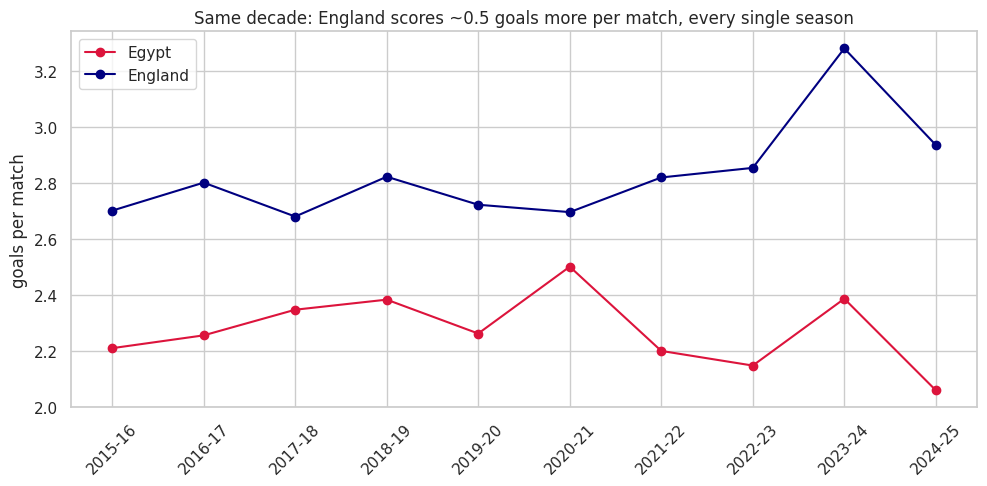

Egypt: 2.29 | England: 2.83


In [22]:
# Chart 1: goals per match, season by season
egy_gpm = results.groupby('SeasonShort')['TotalGoals'].mean()
epl_gpm = epl.groupby('Season')['TotalGoals'].mean()

fig, ax = plt.subplots()
ax.plot(egy_gpm.index, egy_gpm.values, marker='o', color='crimson', label='Egypt')
ax.plot(epl_gpm.index, epl_gpm.values, marker='o', color='navy', label='England')
ax.set_title('Same decade: England scores ~0.5 goals more per match, every single season')
ax.set_ylabel('goals per match')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('Egypt:', round(results['TotalGoals'].mean(), 2), '| England:', round(epl['TotalGoals'].mean(), 2))

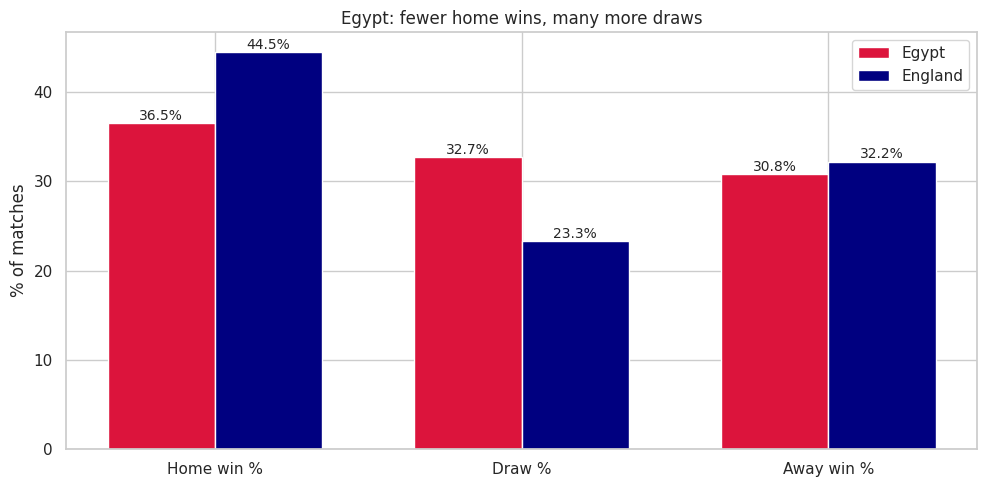

In [23]:
# Chart 2: match outcomes side by side
outcomes = profile.loc[['Home win %', 'Draw %', 'Away win %']]

fig, ax = plt.subplots()
x = range(len(outcomes))
width = 0.35
ax.bar([i - width/2 for i in x], outcomes['Egypt'], width, label='Egypt', color='crimson')
ax.bar([i + width/2 for i in x], outcomes['England'], width, label='England', color='navy')
ax.set_xticks(list(x))
ax.set_xticklabels(outcomes.index)
ax.set_title('Egypt: fewer home wins, many more draws')
ax.set_ylabel('% of matches')
ax.legend()
for i, (eg, en) in enumerate(zip(outcomes['Egypt'], outcomes['England'])):
    ax.text(i - width/2, eg + 0.4, f'{eg}%', ha='center', fontsize=10)
    ax.text(i + width/2, en + 0.4, f'{en}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

The headline: home teams win **44.5%** in England but only **36.5%** in Egypt, and Egypt
has **32.7%** draws vs **23.3%** in England. Section 3 showed the Egyptian reason in the data
(shared and neutral mega-venues, 5.1 "home" stadiums per club on average). In England every
club plays at its own ground in front of its own fans - context from outside the dataset, but
it is the obvious contrast to what the Egyptian stadium table shows.

The COVID season is the natural experiment that ties the two leagues together:

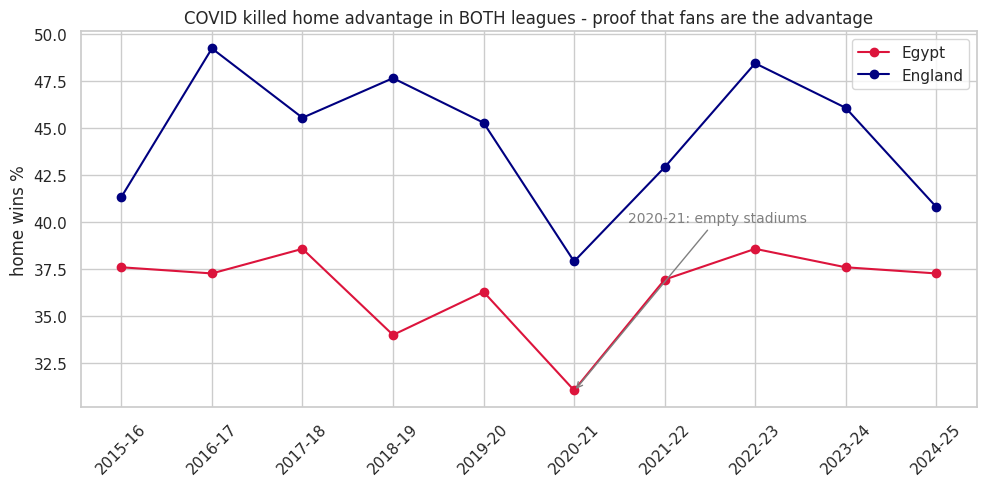

         Egypt 2019-20  Egypt 2020-21
HomeWin           36.3           31.0
Tie               31.7           36.6
AwayWin           32.0           32.4 

   England 2019-20  England 2020-21
H             45.3             37.9
D             24.2             21.8
A             30.5             40.3


In [24]:
# Chart 3: home win % per season in both leagues - watch 2020-21 (COVID, no fans)
egy_home = results.groupby('SeasonShort').apply(
    lambda d: 100 * (d['Status'] == 'HomeWin').mean(), include_groups=False)
epl_home = epl.groupby('Season').apply(
    lambda d: 100 * (d['FTR'] == 'H').mean(), include_groups=False)

fig, ax = plt.subplots()
ax.plot(egy_home.index, egy_home.values, marker='o', color='crimson', label='Egypt')
ax.plot(epl_home.index, epl_home.values, marker='o', color='navy', label='England')
ax.annotate('2020-21: empty stadiums', xy=(5, 31.0), xytext=(5.6, 40),
            fontsize=10, color='gray', arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('COVID killed home advantage in BOTH leagues - proof that fans are the advantage')
ax.set_ylabel('home wins %')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

covid = pd.DataFrame({
    'Egypt 2019-20': results[results['Season'] == '2019-2020']['Status'].value_counts(normalize=True) * 100,
    'Egypt 2020-21': results[results['Season'] == '2020-2021']['Status'].value_counts(normalize=True) * 100,
}, index=['HomeWin', 'Tie', 'AwayWin']).round(1)
epl_covid = pd.DataFrame({
    'England 2019-20': epl[epl['Season'] == '2019-20']['FTR'].value_counts(normalize=True) * 100,
    'England 2020-21': epl[epl['Season'] == '2020-21']['FTR'].value_counts(normalize=True) * 100,
}, index=['H', 'D', 'A']).round(1)
print(covid, '\n')
print(epl_covid)

In 2020-21, with no fans, England's home-win rate crashed from 45.3% to 37.9% (below the
away rate, 40.3%), and Egypt's fell to 31.0% (below 32.4% away). Same league structures,
same pandemic, same collapse - strong evidence that **crowds are a huge part of home
advantage**, which is exactly what Egyptian clubs miss with their attendance restrictions and
neutral venues.

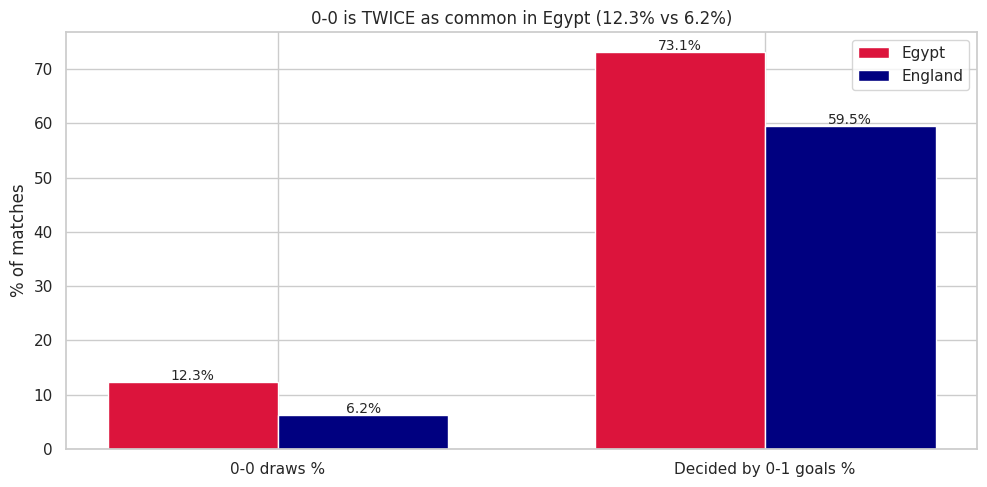

In [25]:
# Chart 4: how tight is each league?
tight = profile.loc[['0-0 draws %', 'Decided by 0-1 goals %']]

fig, ax = plt.subplots()
x = range(len(tight))
width = 0.35
ax.bar([i - width/2 for i in x], tight['Egypt'], width, label='Egypt', color='crimson')
ax.bar([i + width/2 for i in x], tight['England'], width, label='England', color='navy')
ax.set_xticks(list(x))
ax.set_xticklabels(tight.index)
ax.set_title('0-0 is TWICE as common in Egypt (12.3% vs 6.2%)')
ax.set_ylabel('% of matches')
ax.legend()
for i, (eg, en) in enumerate(zip(tight['Egypt'], tight['England'])):
    ax.text(i - width/2, eg + 0.4, f'{eg}%', ha='center', fontsize=10)
    ax.text(i + width/2, en + 0.4, f'{en}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

EPL champions:
          Champion Points
2015-16  Leicester     81
2016-17    Chelsea     93
2017-18   Man City    100
2018-19   Man City     98
2019-20  Liverpool     99
2020-21   Man City     86
2021-22   Man City     93
2022-23   Man City     89
2023-24   Man City     91
2024-25  Liverpool     84


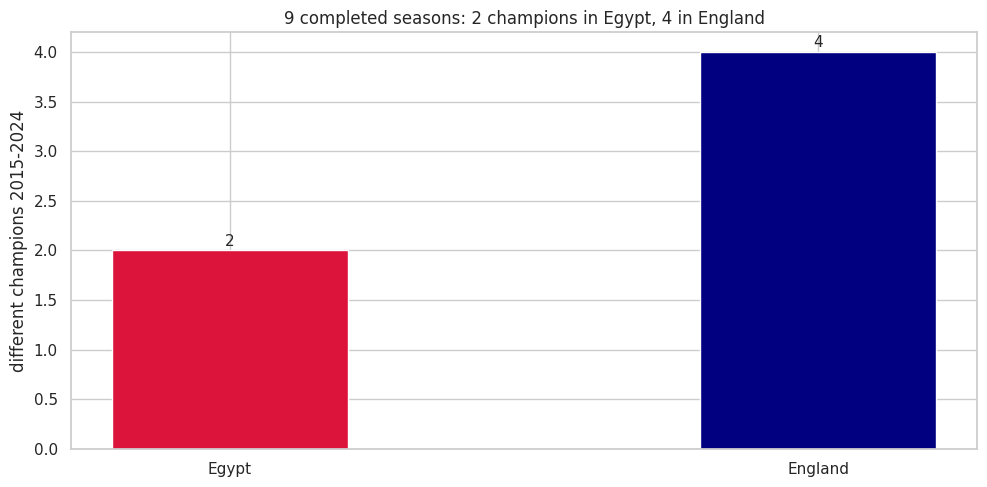

In [26]:
# Competitive balance 1: how many different champions in the 9 completed seasons?
egy_champs = champs['Champion'].value_counts()

epl_champions = {}
for season in sorted(epl['Season'].unique()):
    if season == '2024-25' and False:  # EPL 2024-25 IS complete in this dataset (unlike Egypt's)
        continue
    table = build_league_table(epl[epl['Season'] == season],
                               hg_col='HomeGoals', ag_col='AwayGoals')
    epl_champions[season] = (table.index[0], int(table['Pts'].iloc[0]))

epl_champs = pd.DataFrame(epl_champions, index=['Champion', 'Points']).T
print('EPL champions:')
print(epl_champs)

champ_counts = pd.Series({'Egypt': egy_champs.size,
                          'England': epl_champs['Champion'].nunique()})
fig, ax = plt.subplots()
ax.bar(champ_counts.index, champ_counts.values, color=['crimson', 'navy'], width=0.4)
ax.set_title('9 completed seasons: 2 champions in Egypt, 4 in England')
ax.set_ylabel('different champions 2015-2024')
for i, v in enumerate(champ_counts.values):
    ax.text(i, v + 0.05, str(v), ha='center')
plt.tight_layout()
plt.show()

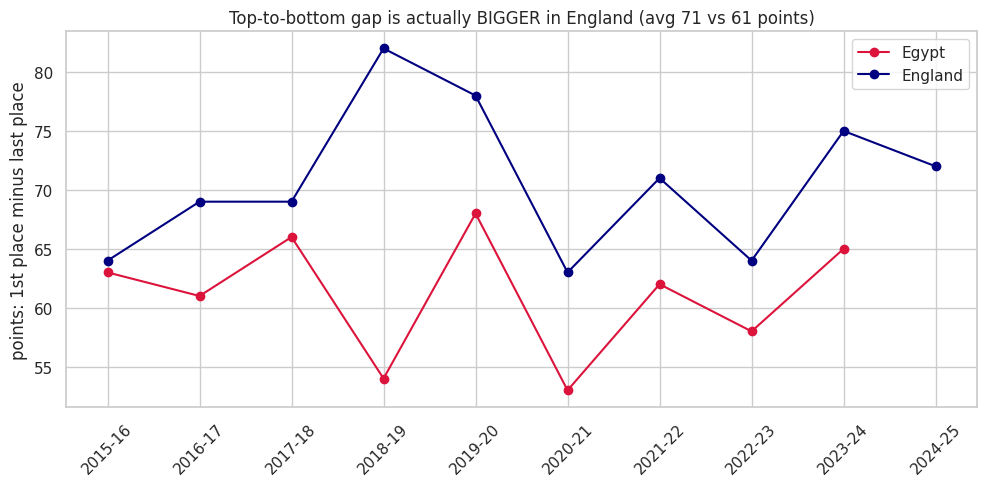

average spread - Egypt: 61.1 | England: 70.7


In [27]:
# Competitive balance 2: points gap between 1st and last, every season
def season_spread(matches, **kwargs):
    table = build_league_table(matches, **kwargs)
    return int(table['Pts'].iloc[0] - table['Pts'].iloc[-1])

egy_spread = {s: season_spread(results[results['Season'] == s]) for s in full_seasons}
epl_spread = {s: season_spread(epl[epl['Season'] == s]) for s in sorted(epl['Season'].unique())}
egy_spread_s = pd.Series(egy_spread); egy_spread_s.index = [s[:4] + '-' + s[7:9] for s in egy_spread_s.index]
epl_spread_s = pd.Series(epl_spread)

fig, ax = plt.subplots()
ax.plot(egy_spread_s.index, egy_spread_s.values, marker='o', color='crimson', label='Egypt')
ax.plot(epl_spread_s.index, epl_spread_s.values, marker='o', color='navy', label='England')
ax.set_title('Top-to-bottom gap is actually BIGGER in England (avg 71 vs 61 points)')
ax.set_ylabel('points: 1st place minus last place')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('average spread - Egypt:', round(egy_spread_s.mean(), 1),
      '| England:', round(epl_spread_s.mean(), 1))

A surprising twist: the points gap between first and last is *bigger* in England (71 vs 61
on average) - the Egyptian league is compressed in the middle. Egypt's imbalance is not the
spread, it's that the **same club almost always wins**: 2 champions in 9 years (Al Ahly 7,
Zamalek 2) vs 4 in England (Man City 5, Liverpool, Chelsea, and Leicester's miracle).

Egypt: 15.3% of goals are penalties (5,447 goals)
England: 7.7% of goals are penalties (8,108 goals)


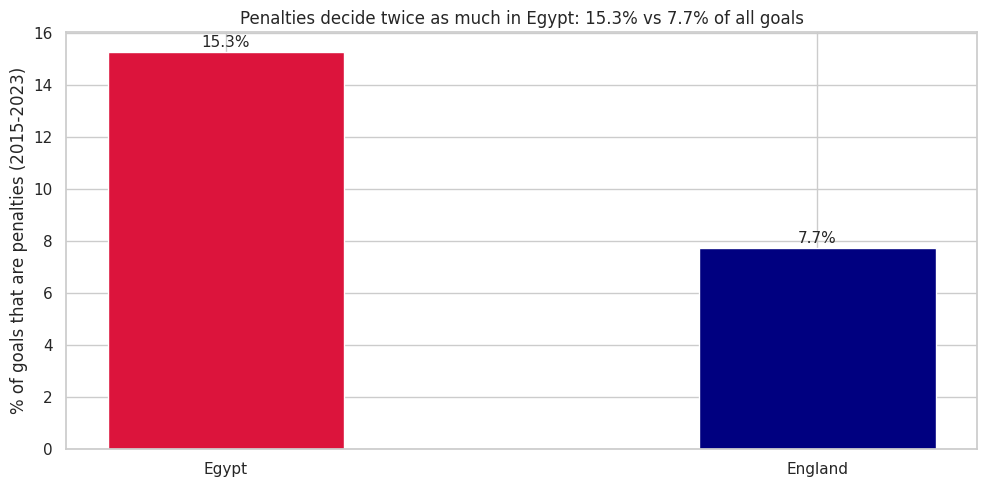

In [28]:
# Penalties: what share of goals come from the spot? (2015-2023 on both sides)
egy_pen = scorer_goals[scorer_goals['Season'] <= '2022-2023']
egy_pen_share = 100 * egy_pen['Penalty'].mean()

epl_goals = pd.read_csv('data/epl_goals_2015_2023.csv')
epl_goals_clean = epl_goals[epl_goals['OwnGoal'] == 0]
epl_pen_share = 100 * epl_goals_clean['Penalty'].mean()

print(f'Egypt: {egy_pen_share:.1f}% of goals are penalties ({len(egy_pen):,} goals)')
print(f'England: {epl_pen_share:.1f}% of goals are penalties ({len(epl_goals_clean):,} goals)')

fig, ax = plt.subplots()
ax.bar(['Egypt', 'England'], [egy_pen_share, epl_pen_share], color=['crimson', 'navy'], width=0.4)
ax.set_title('Penalties decide twice as much in Egypt: 15.3% vs 7.7% of all goals')
ax.set_ylabel('% of goals that are penalties (2015-2023)')
for i, v in enumerate([egy_pen_share, epl_pen_share]):
    ax.text(i, v + 0.2, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

When a league scores few goals, every penalty matters more - and Egyptian matches produce
penalties at a similar raw rate, so they end up being **15.3% of all goals vs 7.7% in
England**. One in six Egyptian goals is a penalty. That is why a single refereeing decision
can flip an entire Egyptian title race.

### The comparison in one table

In [29]:
profile

,Egypt,England
Goals per match,2.3,2.8
Home win %,36.5,44.5
Draw %,32.7,23.3
Away win %,30.8,32.2
Home goals per match,1.2,1.6
0-0 draws %,12.3,6.2
Decided by 0-1 goals %,73.1,59.5


## 9. What I found (summary)

**Egyptian league, 10 seasons:**
1. **A low-scoring league that isn't changing:** 2.29 goals per match on average, flat across
   10 seasons.
2. **Home advantage barely exists:** home teams win 36.5% vs 30.8% away. The stadium data
   explains why: the average club used 5.1 different "home" stadiums, and 3 mega-venues host
   32.8% of all matches. Attendance restrictions (context outside the dataset) add to it, and
   the COVID season - away wins 99 vs home wins 95 - shows what happens with no crowds at all.
3. **Al Ahly dominate like almost nobody else:** 7 of 9 completed titles, a 72.4% win rate,
   and in 2019-20 they conceded **8 goals in 34 matches**.
4. **Abdallah El Said is the scorer of the decade** with 76 goals, ahead of Hossam Hassan
   (69, the Smouha/Ittihad striker, not the 1966 legend) and Zizo (61); I split two namesake
   merges in the raw data to get there. **15.4%** of all goals are penalties.
5. **The league is tight:** 73.1% of matches are decided by 0-1 goals, and 12.3% end 0-0.

**Egypt vs England, same 10 seasons (3,800 EPL matches):**
6. England scores more: **2.83 vs 2.29** goals per match, every single season, and England is
   trending up (record 3.28 in 2023-24) while Egypt stays flat.
7. Home advantage: **44.5% vs 36.5%** home wins; draws **23.3% vs 32.7%**; 0-0 is twice as
   common in Egypt (**12.3% vs 6.2%**).
8. COVID killed home advantage in **both** leagues in 2020-21 (England 45.3% -> 37.9%,
   Egypt 36.3% -> 31.0%) - the cleanest proof that fans are the advantage.
9. Different kinds of imbalance: England has a bigger top-to-bottom points gap (71 vs 61 on
   average), but Egypt has only **2 champions in 9 years vs 4 in England**.
10. Penalties: **15.4% of Egyptian goals vs 7.7% of English goals** (2015-2023).

## 10. Ideas to take this further

- Predict match results with a simple model (logistic regression on home/away + team strength).
- Add the referee table: do some referees give more penalties? (Very relevant after finding 10!)
- Scrape the missing 2024-25 run-in and check whether Pyramids held on to their first title.
- Add a third league (Spain or Saudi Arabia) to see whether Egypt or England is the outlier.
